# 02 — Retreino: o que tentamos e o que aprendemos

O `retraining_pipeline` rodou **três vezes** dentro do laço semanal (semanas 5, 11 e 14). Cada tentativa constrói dois candidatos
(**A**: o campeão recalibrado; **B**: o modelo reajustado na Referência mais as semanas rotuladas) e só troca o campeão se um
portão por bootstrap pareado aprovar. Este notebook só **lê** o que o pipeline registrou no MLflow: não treina nem promove
modelos. A pergunta é: **retreinar ajudou, e o portão decidiu certo?**

In [1]:
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from credit_drift.data import TARGET
from credit_drift.retraining import analysis
from credit_drift.retraining.candidates import features_of
from credit_drift.retraining.window import build_window
from credit_drift.serving.registry import load_champion
from credit_drift.split import REFERENCE_DIR

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
runs = {r["run_week"]: r for r in analysis.retraining_runs()}
champion = load_champion()
BASE = "v1 (campeão)"


def compare(run, weeks, extra=None):
    """Todos os modelos pontuam as MESMAS semanas, que nenhum deles viu no ajuste."""
    names = {BASE: champion.version, "A": run["versions"]["A"], "B": run["versions"]["B"], **(extra or {})}
    scored = analysis.score_weeks(names, weeks)
    weekly = analysis.per_week(scored, list(names)).pivot(index="week", columns="model", values="auc_pr").round(3)
    keep = ("auc_pr", "auc_pr_low", "auc_pr_high", "cost", "cost_low", "cost_high", "brier")
    gaps = pd.DataFrame([{"modelo": n, **{k: round(v, 4) for k, v in analysis.gap(scored, BASE, n).items() if k in keep}}
                         for n in names if n != BASE]).set_index("modelo")
    segment = pd.DataFrame([{"grupo": label, "modelo": n, "AUC-PR": round(analysis.metrics(scored[mask], n)["auc_pr"], 3)}
                            for label, mask in (("dentro do segmento", scored["in_segment"]), ("fora do segmento", ~scored["in_segment"]))
                            for n in names]).pivot(index="grupo", columns="modelo", values="AUC-PR")
    return scored, weekly, gaps, segment

C:\pos tech\tech-challenge-04\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. As três tentativas e o veredito do portão

O portão exige que o IC do **ganho de custo** (C_FN = 5 × C_FP) fique inteiro acima de zero, que o AUC-PR não piore de forma
significativa e que o Brier vença o preditor constante. Com dois candidatos por tentativa, cada um usa intervalo de 97,5%.

In [2]:
rows = []
for week, run in sorted(runs.items()):
    for key in ("A", "B"):
        g = run["gates"][key]
        rows.append({"semana": week, "gatilho": run["trigger"], "rótulos até": run["through_week"], "candidato": f"{key} (v{run['versions'][key]})",
                     "ganho de custo (IC)": f"{g['cost_gain']:+.4f} [{g['cost_gain_ci'][0]:+.4f}, {g['cost_gain_ci'][1]:+.4f}]",
                     "AUC-PR dif. (IC)": f"{g['auc_pr_diff']:+.3f} [{g['auc_pr_diff_ci'][0]:+.3f}, {g['auc_pr_diff_ci'][1]:+.3f}]",
                     "passou": g["passed"]})
print("fatia do portão:", runs[5]["gates"]["A"]["rows"], "linhas,", runs[5]["gates"]["A"]["defaulters"], "inadimplentes")
pd.DataFrame(rows).set_index(["semana", "gatilho", "rótulos até", "candidato"])

fatia do portão: 8000 linhas, 640 inadimplentes


ganho de custo (IC)  \
semana gatilho          rótulos até candidato                               
5      data_drift_major 4           A (v18)    -0.0031 [-0.0093, +0.0021]   
                                    B (v19)    -0.0106 [-0.0243, +0.0024]   
11     performance_drop 10          A (v20)    +0.0008 [-0.0088, +0.0093]   
                                    B (v21)    +0.0039 [-0.0088, +0.0169]   
14     performance_drop 13          A (v22)    +0.0012 [-0.0073, +0.0097]   
                                    B (v23)    -0.0028 [-0.0147, +0.0093]   

                                                      AUC-PR dif. (IC)  passou  
semana gatilho          rótulos até candidato                                   
5      data_drift_major 4           A (v18)    +0.000 [+0.000, +0.000]   False  
                                    B (v19)    -0.011 [-0.027, +0.004]   False  
11     performance_drop 10          A (v20)    +0.000 [+0.000, +0.000]   False  
                                    B (v21)    -0.001 [-0.014, +0.011]   False  
14     performance_drop 13          A (v22)    +0.000 [+0.000, +0.000]   False  
                                    B (v23)    -0.005 [-0.017, +0.009]   False

## 2. Tentativa 1 (semana 5): drift de covariáveis

Rótulos só até a semana 4. Os candidatos são avaliados nas semanas 6 a 16 (sem a 9, que não tem rótulos).

In [3]:
W5 = [6, 7, 8, 10, 11, 12, 13, 14, 15, 16]
scored5, weekly5, gaps5, segment5 = compare(runs[5], W5)
weekly5

model,A,B,v1 (campeão)
week,,,
6,0.252,0.235,0.252
7,0.263,0.250,0.263
8,0.182,0.167,0.182
10,0.196,0.172,0.196
11,0.176,0.174,0.176
12,0.212,0.202,0.212
13,0.206,0.205,0.206
14,0.198,0.187,0.198
15,0.214,0.211,0.214


In [4]:
gaps5

,auc_pr,auc_pr_low,auc_pr_high,brier,cost,cost_low,cost_high
modelo,,,,,,,
A,0.0000,0.0000,0.0000,-0.0001,-0.0011,-0.0029,0.0008
B,-0.0097,-0.0139,-0.0056,0.0004,0.0046,-0.0002,0.0095


In [5]:
segment5

modelo,A,B,v1 (campeão)
grupo,,,
dentro do segmento,0.197,0.191,0.197
fora do segmento,0.210,0.199,0.210


**Leitura.** O drift das semanas 3–5 é de covariáveis: o ranking do modelo quase não muda. Recalibrar (A) é neutro: mesmo
AUC-PR do v1 em todas as semanas e custo praticamente igual. Reajustar o modelo (B) com 4 semanas rotuladas foi **pior**:
AUC-PR −0,010 (IC 95% −0,014 a −0,006) nas semanas 6–16. O portão acertou ao recusar os dois. Retreinar não é sempre a resposta:
recalibrar é a correção barata, e aqui nem ela se pagou.

## 3. Tentativa 3 (semana 14): cinco semanas rotuladas de drift de conceito

Rótulos até a semana 13, com as semanas 8, 10, 11, 12 e 13 já no regime novo. Avaliação nas semanas 14 a 16, que nenhum
candidato viu. Incluímos também o candidato B das tentativas 1 e 2, para ver o efeito de ter mais evidência.

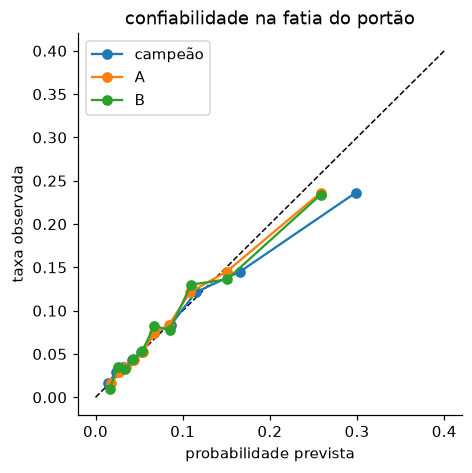

In [6]:
run14 = runs[14]
window = build_window(run14["through_week"], pd.read_parquet(REFERENCE_DIR / "train.parquet"))
gate = window.gate.reset_index(drop=True)
versions = {"campeão": champion.version, "A": run14["versions"]["A"], "B": run14["versions"]["B"]}
models = {n: mlflow.sklearn.load_model(f"models:/credit_scoring/{v}") for n, v in versions.items()}
X = features_of(gate)
frame = pd.DataFrame({TARGET: gate[TARGET].to_numpy(), **{n: m.predict_proba(X)[:, 1] for n, m in models.items()}})
fig, ax = plt.subplots(figsize=(4.5, 4.5)); ax.plot([0, 0.4], [0, 0.4], "k--", lw=1)
for name in versions:
    table = analysis.reliability(frame, name); ax.plot(table["predicted"], table["observed"], "o-", label=name)
ax.set_xlabel("probabilidade prevista"); ax.set_ylabel("taxa observada"); ax.set_title("confiabilidade na fatia do portão"); ax.legend(); plt.show()

In [7]:
extra = {"retreino 2 (B)": runs[11]["versions"]["B"], "retreino 1 (B)": runs[5]["versions"]["B"]}
scored14, weekly14, gaps14, segment14 = compare(run14, [14, 15, 16], extra)
weekly14

model,A,B,retreino 1 (B),retreino 2 (B),v1 (campeão)
week,,,,,
14,0.198,0.213,0.187,0.201,0.198
15,0.214,0.227,0.211,0.218,0.214
16,0.180,0.182,0.172,0.183,0.180


In [8]:
gaps14

,auc_pr,auc_pr_low,auc_pr_high,brier,cost,cost_low,cost_high
modelo,,,,,,,
A,0.0000,0.0000,0.0000,-0.0004,-0.0015,-0.0067,0.0040
B,0.0113,0.0024,0.0200,-0.0009,-0.0068,-0.0146,0.0009
retreino 2 (B),0.0050,-0.0021,0.0127,-0.0005,-0.0082,-0.0165,-0.0006
retreino 1 (B),-0.0075,-0.0149,0.0002,0.0002,0.0024,-0.0059,0.0111


In [9]:
segment14

modelo,A,B,retreino 1 (B),retreino 2 (B),v1 (campeão)
grupo,,,,,
dentro do segmento,0.189,0.216,0.182,0.199,0.189
fora do segmento,0.204,0.201,0.198,0.203,0.204


**Leitura.** Com cinco semanas de drift de conceito, o candidato B (v23) **melhora de fato** nas semanas 14–16: AUC-PR +0,011
(IC 95% +0,002 a +0,020). O ganho está onde o drift foi injetado: dentro do segmento o AUC-PR vai de 0,189 para 0,216, e fora dele fica
igual. A recalibração (A) não muda o AUC-PR, como previsto: o ranking continua errado. O retreino 2 (duas semanas de drift) aponta na
direção certa, mas o intervalo inclui zero, e o retreino 1 (covariáveis) é pior.

**Mas o portão não aprovou.** Na fatia dele (8 mil linhas, 668 inadimplentes) o B teve AUC-PR −0,005 (IC −0,017 a +0,009). As duas
estimativas (+0,011 e −0,005) cabem no ruído de amostragem de uma fatia desse tamanho.

## 4. Conclusão

- **Covariáveis:** retreinar não ajuda, e o portão evita uma troca que pioraria o modelo.
- **Conceito:** retreinar ajuda, e o ganho cresce com as semanas rotuladas do regime novo (2 semanas: indistinguível de zero; 5 semanas: +0,011).
- **O portão é conservador:** com cerca de 5 mil clientes por semana e 8% de inadimplência, um ganho de um ponto de AUC-PR não é certificável
  numa validação curta. Em produção isso pede um período de sombra mais longo, em que o desafiante acumula rótulos antes de ser promovido.
- Parte do desenho do portão foi ajustada depois de ver resultados; está registrado como post hoc na decisão 18.